In [1]:
import os
import pandas as pd
import numpy as np
from dotenv import load_dotenv
from sqlalchemy import create_engine

from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from lightgbm import LGBMClassifier

import shap
import matplotlib.pyplot as plt

In [2]:
load_dotenv()
engine = create_engine(os.getenv("DATABASE_URL"))

query = '''
SELECT *
FROM hpce.churn_model_dataset
WHERE feature_date <= '2018-08-04'
'''
df = pd.read_sql(query, engine)

df["feature_date"] = pd.to_datetime(df["feature_date"]).dt.date

print(df.shape)
print("Date range:", df["feature_date"].min(), "->", df["feature_date"].max())

(342173, 26)
Date range: 2016-09-04 -> 2018-08-04


In [3]:
FEATURES = [
    "daily_orders",
    "daily_spend",
    "f_30",
    "m_30",
    "f_trend_30",
    "m_trend_30",
    "recency_days"
]

TARGET = "churn_30d"

# Safety check
missing = set(FEATURES + [TARGET]) - set(df.columns)
if missing:
    raise ValueError(f"Missing columns in df: {missing}")

df[FEATURES] = df[FEATURES].astype(float)
df[TARGET] = df[TARGET].astype(int)

In [4]:
cutoff = pd.to_datetime("2018-07-01").date()

train = df[df["feature_date"] <= cutoff].copy()
test  = df[df["feature_date"] >  cutoff].copy()

X_train = train[FEATURES]
y_train = train[TARGET]

X_test  = test[FEATURES]
y_test  = test[TARGET]

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Test base rate:", float(y_test.mean()))

Train: (327448, 7) Test: (14725, 7)
Test base rate: 0.5836332767402377


In [5]:
lgbm = LGBMClassifier(
    objective="binary",
    boosting_type="gbdt",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

lgbm.fit(X_train, y_train)

[LightGBM] [Info] Number of positive: 278426, number of negative: 49022
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002220 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1041
[LightGBM] [Info] Number of data points in the train set: 327448, number of used features: 7
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.05
,n_estimators,300
,subsample_for_bin,200000
,objective,'binary'
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [6]:
probs = lgbm.predict_proba(X_test)[:, 1]

print("LGBM ROC-AUC:", roc_auc_score(y_test, probs))
print("LGBM PR-AUC :", average_precision_score(y_test, probs))

eval_df = test.copy()
eval_df["pred"] = probs
eval_df.head()

LGBM ROC-AUC: 0.9129400893311181
LGBM PR-AUC : 0.9476543686348815


,customer_id,feature_date,daily_orders,daily_spend,f_30,m_30,f_30_prev30,f_trend_30,m_30_prev30,m_trend_30,...,m_90,f_90_prev90,f_trend_90,m_90_prev90,m_trend_90,recency_days,churn_30d,churn_60d,churn_90d,pred
21,000fbf0473c10fc1ab6f8d2d286ce20c,2018-07-26,1.0,362.36,1.0,362.36,0.0,1.0,0.0,362.36,...,362.36,0.0,1.0,0.0,362.36,0.0,1,1,1,0.965014
31,0015752e079902b12cd00b9b7596276b,2018-08-02,1.0,74.82,1.0,74.82,0.0,1.0,0.0,74.82,...,74.82,0.0,1.0,0.0,74.82,0.0,1,1,1,0.973430
32,00172711b30d52eea8b313a7f2cced02,2018-07-28,1.0,122.07,1.0,122.07,0.0,1.0,0.0,122.07,...,122.07,0.0,1.0,0.0,122.07,0.0,1,1,1,0.949031
35,00196c4c9a3af7dd2ad10eade69c926f,2018-07-28,1.0,37.58,1.0,37.58,0.0,1.0,0.0,37.58,...,37.58,0.0,1.0,0.0,37.58,0.0,1,1,1,0.960135
40,001a34eb30ecb8e3aacb07c475ca4dd1,2018-07-11,1.0,161.71,1.0,161.71,0.0,1.0,0.0,161.71,...,161.71,0.0,1.0,0.0,161.71,0.0,1,1,1,0.970791


In [7]:
imp = pd.Series(lgbm.feature_importances_, index=FEATURES).sort_values(ascending=False)
imp

m_trend_30      2885
m_30            2737
recency_days    1795
f_trend_30       618
f_30             433
daily_spend      430
daily_orders     102
dtype: int32

In [8]:
X_exp = (
    X_test
    .sample(n=min(5000, len(X_test)), random_state=42)
    .astype(float)
)

explainer = shap.TreeExplainer(lgbm)

shap_values = explainer.shap_values(
    X_exp,
    check_additivity=False
)

if isinstance(shap_values, list):
    shap_values = shap_values[1]


D:\Thompson Rivers University\3rd Semester\Grad Project on Data Science\Final Year Design Project\hyper-personalized-customer-engine\.venv\Lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


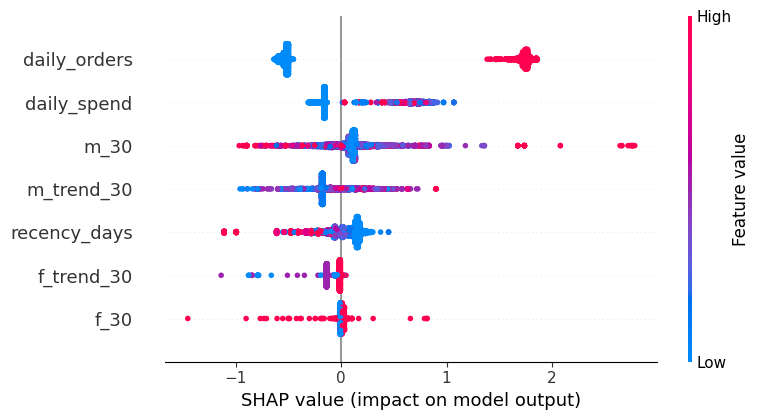

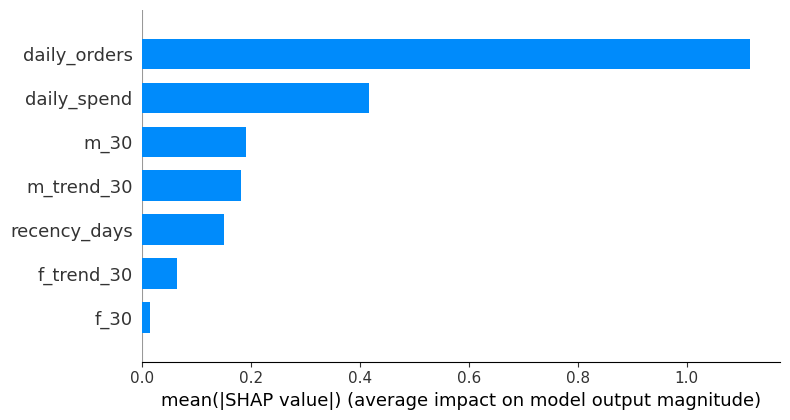

In [9]:
shap.summary_plot(shap_values, X_exp)                  # beeswarm
shap.summary_plot(shap_values, X_exp, plot_type="bar") # global importance

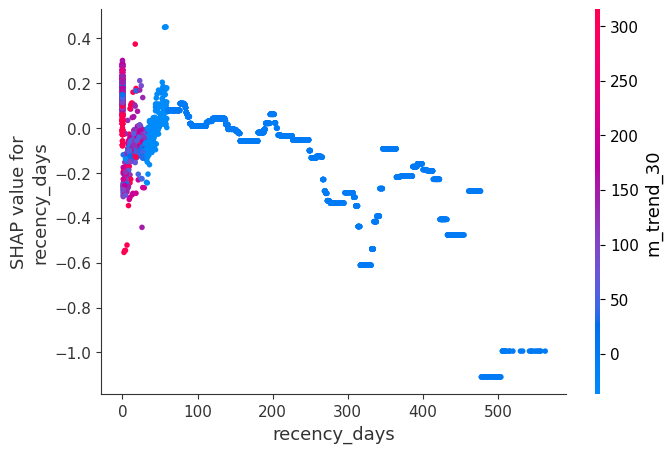

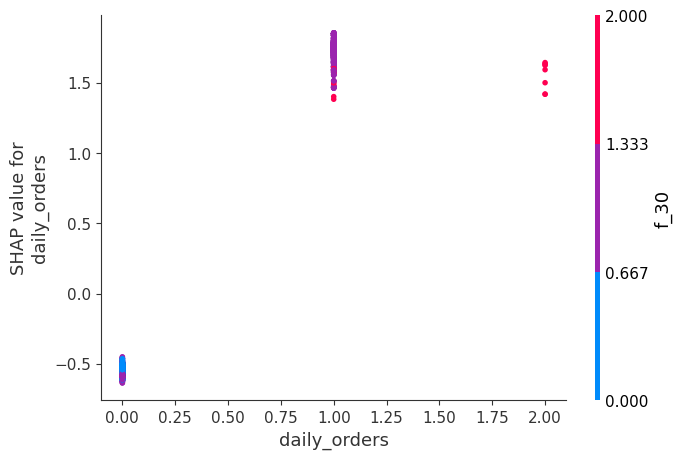

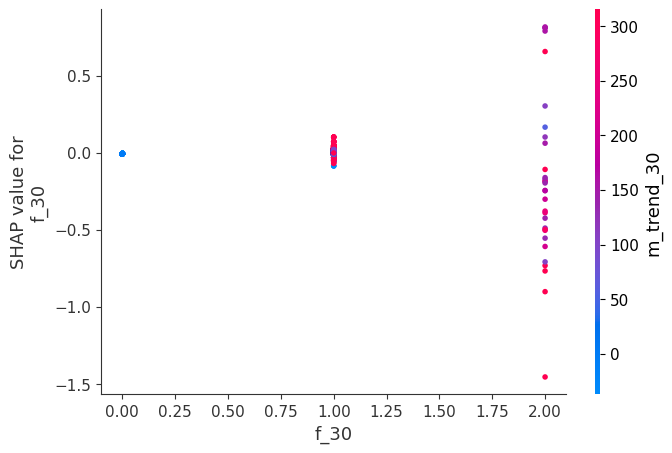

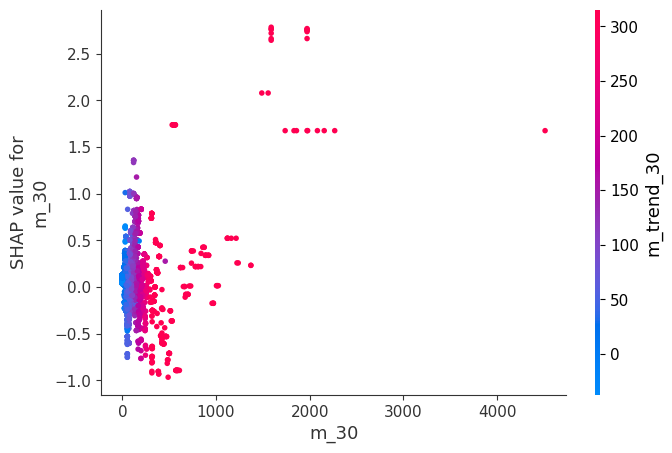

In [10]:
for feat in ["recency_days", "daily_orders", "f_30", "m_30"]:
    shap.dependence_plot(feat, shap_values, X_exp, show=True)

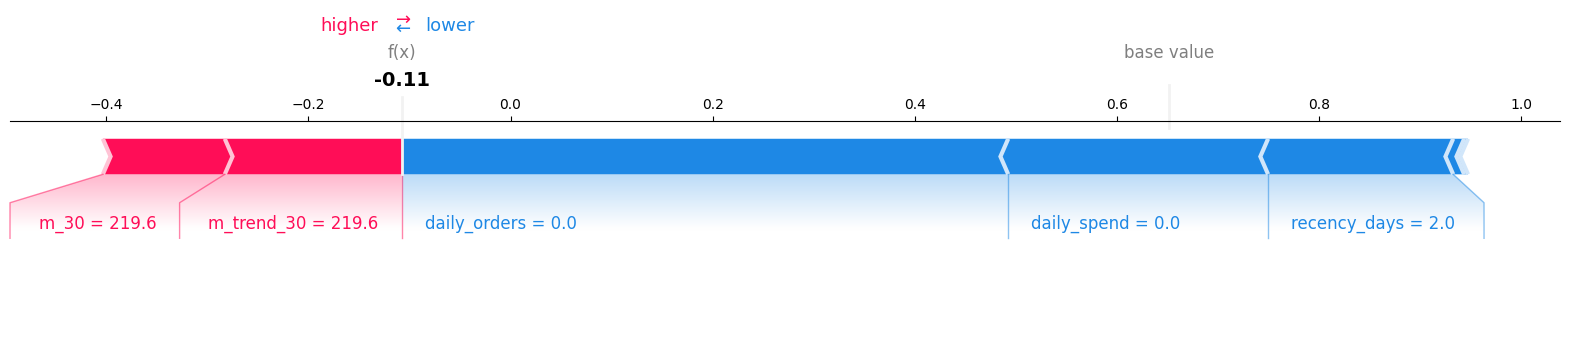

In [11]:
idx = X_exp.index[0]

shap.force_plot(
    explainer.expected_value,
    shap_values[X_exp.index.get_loc(idx)],
    X_exp.loc[idx],
    matplotlib=True
)

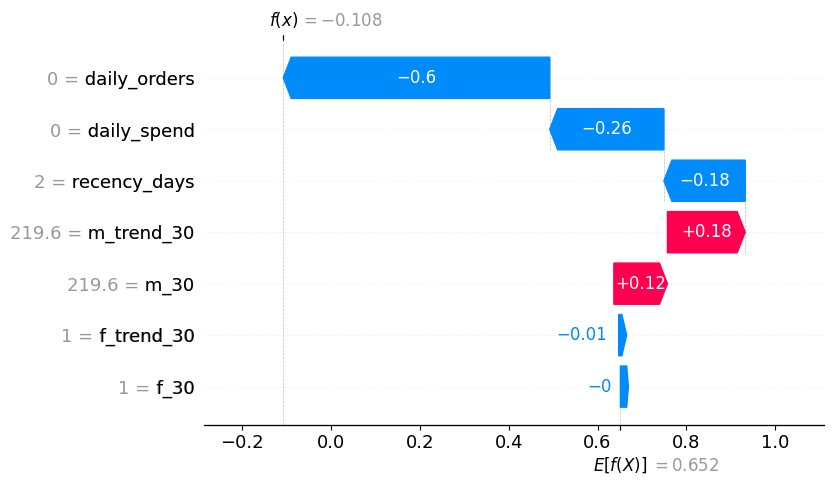

In [12]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[X_exp.index.get_loc(idx)],
        base_values=explainer.expected_value,
        data=X_exp.loc[idx],
        feature_names=X_exp.columns
    )
)

In [13]:
preds = lgbm.predict_proba(X_exp)[:, 1]
shap_sum = shap_values.sum(axis=1) + explainer.expected_value

pd.DataFrame({
    "prediction": preds,
    "shap_sum": shap_sum
}).corr()

,prediction,shap_sum
prediction,1.000000,0.990262
shap_sum,0.990262,1.000000


In [14]:
df_shap = X_exp.copy()
df_shap["churn_prob"] = preds
df_shap["abs_shap_sum"] = np.abs(shap_values).sum(axis=1)

df_shap.sort_values(
    ["churn_prob", "abs_shap_sum"],
    ascending=False
).head(10)

,daily_orders,daily_spend,f_30,m_30,f_trend_30,m_trend_30,recency_days,churn_prob,abs_shap_sum
265902,1.0,1488.59,1.0,1488.59,1.0,1488.59,0.0,0.992746,4.296378
63519,1.0,1556.67,1.0,1556.67,1.0,1556.67,0.0,0.992746,4.296378
103702,1.0,543.29,1.0,543.29,1.0,543.29,0.0,0.992097,4.197023
159553,1.0,550.83,1.0,550.83,1.0,550.83,0.0,0.992097,4.197023
16077,1.0,554.94,1.0,554.94,1.0,554.94,0.0,0.992097,4.197023
310999,1.0,549.70,1.0,549.70,1.0,549.70,0.0,0.992097,4.197023
287925,1.0,545.47,1.0,545.47,1.0,545.47,0.0,0.992097,4.197023
173813,1.0,549.70,1.0,549.70,1.0,549.70,0.0,0.992097,4.197023
113106,1.0,543.90,1.0,543.90,1.0,543.90,0.0,0.992097,4.197023
225501,1.0,540.76,1.0,540.76,1.0,540.76,0.0,0.992097,4.197023
